In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the generated feature dataset

data_path = r"C:\ML PROJECT\DATASET\segmentation_features.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (2192, 11)

First 5 rows:


,image_name,tumor_type,tumor_area,tumor_percentage,tumor_width,tumor_height,aspect_ratio,mean_intensity,std_intensity,min_intensity,max_intensity
0,enh_1841.png,Glioma,5973,2.278519,88,85,1.035294,118.261678,63.219609,1,242
1,enh_1842.png,Glioma,6523,2.488327,90,89,1.011236,116.281159,60.558850,1,236
2,enh_1843.png,Glioma,5800,2.212524,86,92,0.934783,114.764138,56.469622,1,236
3,enh_1844.png,Glioma,3352,1.278687,65,61,1.065574,103.958532,44.343451,13,212
4,enh_1845.png,Glioma,9911,3.780746,106,128,0.828125,149.474725,48.307842,1,254


In [3]:
# Separate input features and target variable

X = df.drop(columns=["image_name", "tumor_type"])
y = df["tumor_type"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

Features shape: (2192, 9)
Target shape: (2192,)

Feature columns:
['tumor_area', 'tumor_percentage', 'tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']

Target classes:
<StringArray>
['Glioma', 'Meningioma', 'Pituitary tumor']
Length: 3, dtype: str


In [4]:
# Split data into training, validation, and test sets

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Dataset split completed!")

print("\nTraining:")
print("Features:", X_train.shape)
print("Labels:", y_train.shape)

print("\nValidation:")
print("Features:", X_val.shape)
print("Labels:", y_val.shape)

print("\nTest:")
print("Features:", X_test.shape)
print("Labels:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Dataset split completed!

Training:
Features: (1534, 9)
Labels: (1534,)

Validation:
Features: (329, 9)
Labels: (329,)

Test:
Features: (329, 9)
Labels: (329,)

Training class distribution:
tumor_type
Pituitary tumor    651
Meningioma         495
Glioma             388
Name: count, dtype: int64

Validation class distribution:
tumor_type
Pituitary tumor    140
Meningioma         106
Glioma              83
Name: count, dtype: int64

Test class distribution:
tumor_type
Pituitary tumor    139
Meningioma         107
Glioma              83
Name: count, dtype: int64


In [5]:
# Scale numerical features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("\nTraining scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)

print("\nTraining scaled feature means:")
print(np.mean(X_train_scaled, axis=0))

print("\nTraining scaled feature standard deviations:")
print(np.std(X_train_scaled, axis=0))

Feature scaling completed!

Training scaled shape: (1534, 9)
Validation scaled shape: (329, 9)
Test scaled shape: (329, 9)

Training scaled feature means:
[-7.41113675e-17 -3.47397035e-17  1.32010873e-16  1.48222735e-16
  9.03232291e-17  3.58976936e-17 -4.72459968e-16  2.54757826e-17
  1.91647364e-16]

Training scaled feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [51]:
# Save the classification scaler for deployment

import joblib

classification_scaler_path = r"C:\ML PROJECT\DATASET\classification_scaler.pkl"

joblib.dump(
    scaler,
    classification_scaler_path
)

print("Classification scaler saved successfully!")
print("File:", classification_scaler_path)

Classification scaler saved successfully!
File: C:\ML PROJECT\DATASET\classification_scaler.pkl


In [6]:
# Train Logistic Regression model

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [7]:
# Evaluate Logistic Regression on validation data

from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_val_pred = logistic_model.predict(X_val_scaled)

# Calculate accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Logistic Regression Validation Accuracy:",
      f"{val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Logistic Regression Validation Accuracy: 0.6505

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.52      0.14      0.23        83
     Meningioma       0.60      0.86      0.71       106
Pituitary tumor       0.72      0.79      0.76       140

       accuracy                           0.65       329
      macro avg       0.61      0.60      0.56       329
   weighted avg       0.63      0.65      0.61       329



In [47]:
# Save final Logistic Regression model

import joblib

classification_model_path = r"C:\ML PROJECT\DATASET\final_logistic_regression_model.pkl"

joblib.dump(logistic_model, classification_model_path)

print("Final Logistic Regression model saved successfully!")
print("File:", classification_model_path)

Final Logistic Regression model saved successfully!
File: C:\ML PROJECT\DATASET\final_logistic_regression_model.pkl


In [8]:
# Train K-Nearest Neighbors (KNN) model

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

print("KNN training completed!")

KNN training completed!


In [9]:
# Evaluate KNN on validation data

y_val_pred_knn = knn_model.predict(X_val_scaled)

knn_val_accuracy = accuracy_score(y_val, y_val_pred_knn)

print("KNN Validation Accuracy:",
      f"{knn_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_knn))

KNN Validation Accuracy: 0.6474

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.49      0.46      0.47        83
     Meningioma       0.62      0.75      0.68       106
Pituitary tumor       0.78      0.69      0.73       140

       accuracy                           0.65       329
      macro avg       0.63      0.63      0.63       329
   weighted avg       0.65      0.65      0.65       329



In [10]:
# Train Gaussian Naive Bayes model

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

print("Gaussian Naive Bayes training completed!")

Gaussian Naive Bayes training completed!


In [11]:
# Evaluate Gaussian Naive Bayes on validation data

y_val_pred_nb = nb_model.predict(X_val_scaled)

nb_val_accuracy = accuracy_score(y_val, y_val_pred_nb)

print("Gaussian Naive Bayes Validation Accuracy:",
      f"{nb_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_nb))

Gaussian Naive Bayes Validation Accuracy: 0.6049

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.36      0.24      0.29        83
     Meningioma       0.59      0.65      0.62       106
Pituitary tumor       0.70      0.79      0.74       140

       accuracy                           0.60       329
      macro avg       0.55      0.56      0.55       329
   weighted avg       0.58      0.60      0.59       329



In [12]:
# Train Decision Tree model

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [13]:
# Evaluate Decision Tree on validation data

y_val_pred_dt = dt_model.predict(X_val)

dt_val_accuracy = accuracy_score(y_val, y_val_pred_dt)

print("Decision Tree Validation Accuracy:",
      f"{dt_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_dt))

Decision Tree Validation Accuracy: 0.6413

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.43      0.46      0.44        83
     Meningioma       0.69      0.75      0.72       106
Pituitary tumor       0.75      0.66      0.70       140

       accuracy                           0.64       329
      macro avg       0.62      0.63      0.62       329
   weighted avg       0.65      0.64      0.64       329



In [14]:
# Train Support Vector Machine (SVM) model

from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

print("SVM training completed!")

SVM training completed!


In [15]:
# Evaluate SVM on validation data

y_val_pred_svm = svm_model.predict(X_val_scaled)

svm_val_accuracy = accuracy_score(y_val, y_val_pred_svm)

print("SVM Validation Accuracy:",
      f"{svm_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm))

SVM Validation Accuracy: 0.6383

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.42      0.23      0.30        83
     Meningioma       0.60      0.78      0.68       106
Pituitary tumor       0.74      0.77      0.76       140

       accuracy                           0.64       329
      macro avg       0.59      0.59      0.58       329
   weighted avg       0.62      0.64      0.62       329



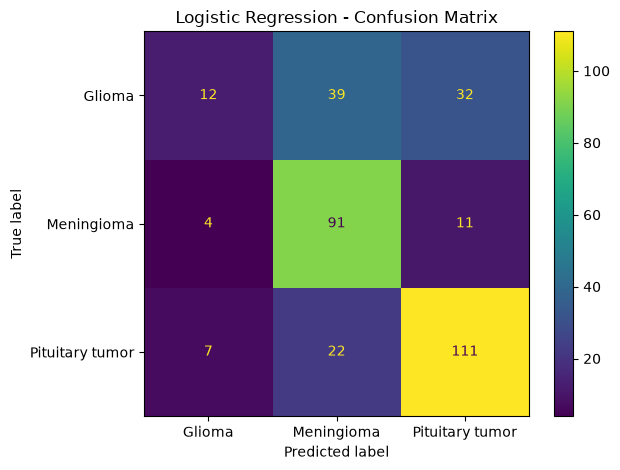

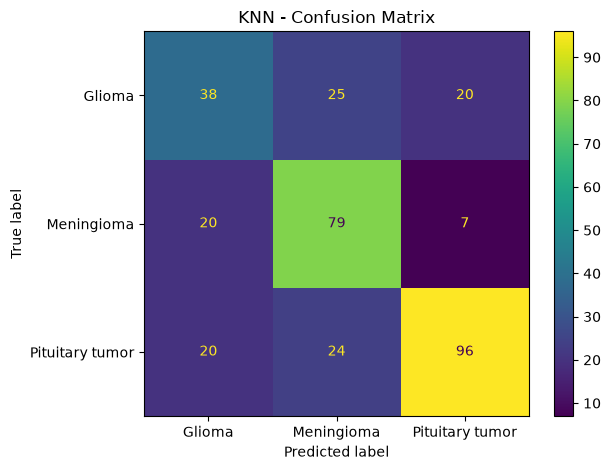

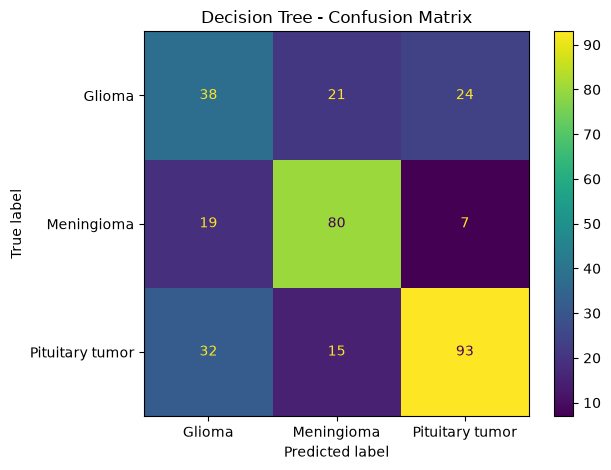

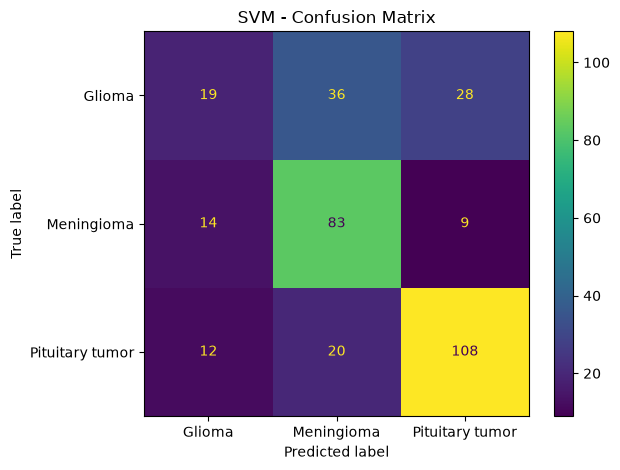

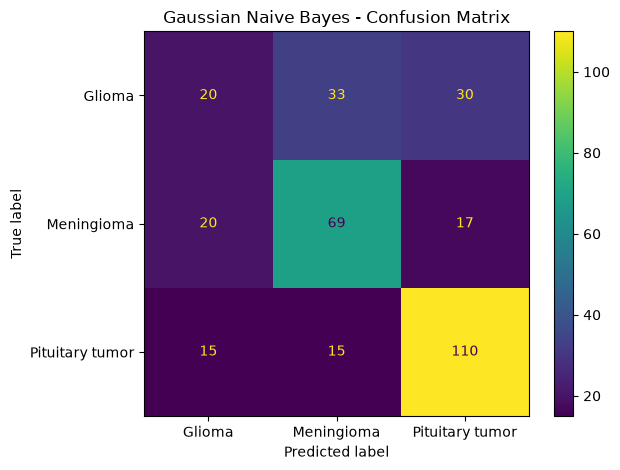

In [48]:
# Confusion matrices for all classification models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

classification_models = {
    "Logistic Regression": y_val_pred,
    "KNN": y_val_pred_knn,
    "Decision Tree": y_val_pred_dt,
    "SVM": y_val_pred_svm,
    "Gaussian Naive Bayes": y_val_pred_nb
}

for model_name, predictions in classification_models.items():

    cm = confusion_matrix(y_val, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Glioma", "Meningioma", "Pituitary tumor"]
    )

    disp.plot()

    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [49]:
# Classification Model Comparison
# Accuracy and Weighted F1-score

from sklearn.metrics import accuracy_score, f1_score

classification_comparison = []

model_predictions = {
    "Logistic Regression": y_val_pred,
    "KNN": y_val_pred_knn,
    "Decision Tree": y_val_pred_dt,
    "SVM": y_val_pred_svm,
    "Gaussian Naive Bayes": y_val_pred_nb
}

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(y_val, predictions)

    weighted_f1 = f1_score(
        y_val,
        predictions,
        average="weighted"
    )

    classification_comparison.append({
        "Model": model_name,
        "Validation Accuracy": round(accuracy, 4),
        "Weighted F1-Score": round(weighted_f1, 4)
    })

classification_comparison_df = pd.DataFrame(
    classification_comparison
)

classification_comparison_df = classification_comparison_df.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)

print("Classification Model Comparison:")
display(classification_comparison_df)

Classification Model Comparison:


,Model,Validation Accuracy,Weighted F1-Score
0,Logistic Regression,0.6505,0.6057
1,KNN,0.6474,0.6473
2,Decision Tree,0.6413,0.6435
3,SVM,0.6383,0.6157
4,Gaussian Naive Bayes,0.6049,0.5877


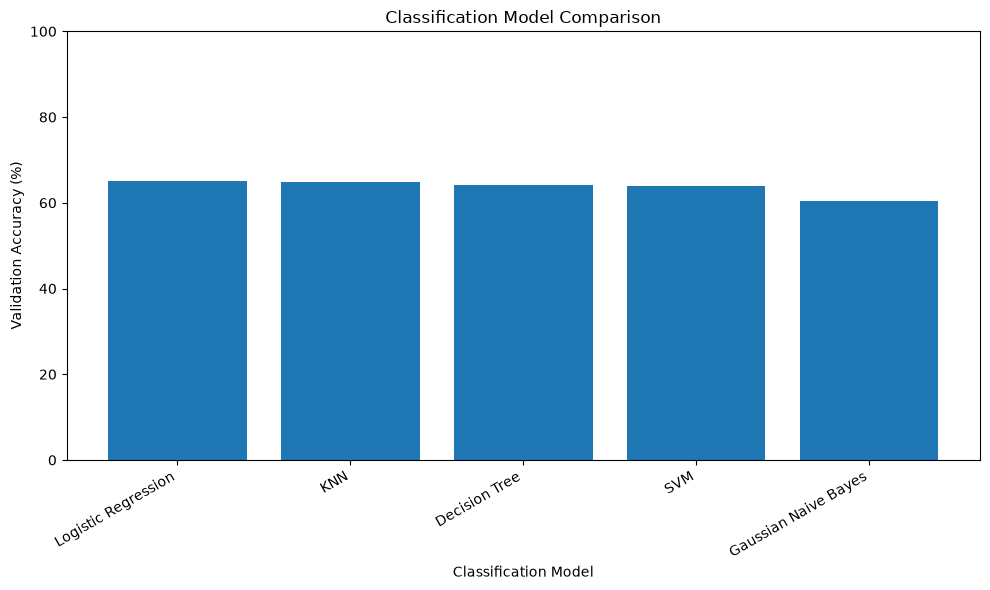

In [53]:
# Visualize model validation accuracy

plt.figure(figsize=(10, 6))

plt.bar(
    classification_comparison_df["Model"],
    classification_comparison_df["Validation Accuracy"] * 100
)

plt.xlabel("Classification Model")
plt.ylabel("Validation Accuracy (%)")
plt.title("Classification Model Comparison")
plt.xticks(rotation=30, ha="right")

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [18]:
# Final evaluation on the unseen test set

from sklearn.metrics import accuracy_score, classification_report

# Logistic Regression
y_test_pred_lr = logistic_model.predict(X_test_scaled)
lr_test_accuracy = accuracy_score(y_test, y_test_pred_lr)

# KNN
y_test_pred_knn = knn_model.predict(X_test_scaled)
knn_test_accuracy = accuracy_score(y_test, y_test_pred_knn)

print("Logistic Regression Test Accuracy:",
      f"{lr_test_accuracy:.4f}")

print("\nLogistic Regression Test Classification Report:")
print(classification_report(y_test, y_test_pred_lr))

print("\n" + "=" * 60 + "\n")

print("KNN Test Accuracy:",
      f"{knn_test_accuracy:.4f}")

print("\nKNN Test Classification Report:")
print(classification_report(y_test, y_test_pred_knn))

Logistic Regression Test Accuracy: 0.6626

Logistic Regression Test Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.48      0.18      0.26        83
     Meningioma       0.66      0.80      0.73       107
Pituitary tumor       0.70      0.84      0.76       139

       accuracy                           0.66       329
      macro avg       0.61      0.61      0.58       329
   weighted avg       0.63      0.66      0.62       329



KNN Test Accuracy: 0.6596

KNN Test Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.46      0.46      0.46        83
     Meningioma       0.69      0.66      0.68       107
Pituitary tumor       0.76      0.78      0.77       139

       accuracy                           0.66       329
      macro avg       0.63      0.63      0.63       329
   weighted avg       0.66      0.66      0.66       329



In [44]:
# Save Logistic Regression test predictions

classification_test_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred_lr
})

classification_test_results.to_csv(
    r"C:\ML PROJECT\DATASET\logistic_test_predictions.csv",
    index=False
)

print("Classification test predictions saved successfully!")
print("File:", r"C:\ML PROJECT\DATASET\logistic_test_predictions.csv")

Classification test predictions saved successfully!
File: C:\ML PROJECT\DATASET\logistic_test_predictions.csv


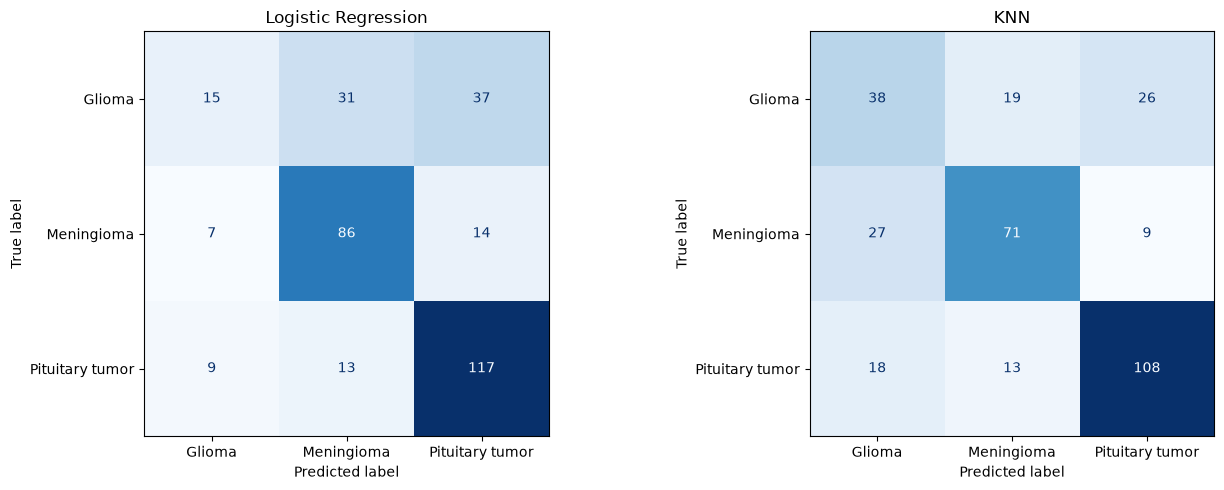

In [19]:
# Compare confusion matrices of Logistic Regression and KNN

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Logistic Regression confusion matrix
cm_lr = confusion_matrix(y_test, y_test_pred_lr)

# KNN confusion matrix
cm_knn = confusion_matrix(y_test, y_test_pred_knn)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=logistic_model.classes_
)
disp_lr.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Logistic Regression")

# KNN
disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=knn_model.classes_
)
disp_knn.plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("KNN")

plt.tight_layout()
plt.show()

In [20]:
# Prepare dataset for Regression Track

import pandas as pd
import numpy as np

# Load the feature dataset
feature_path = r"C:\ML PROJECT\DATASET\segmentation_features.csv"

df_reg = pd.read_csv(feature_path)

# Regression features
regression_features = [
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity"
]

# Regression target
regression_target = "tumor_area"

# Create X and y
X_reg = df_reg[regression_features]
y_reg = df_reg[regression_target]

print("Regression dataset prepared!")

print("\nFeatures shape:", X_reg.shape)
print("Target shape:", y_reg.shape)

print("\nFeature columns:")
print(regression_features)

print("\nTarget:")
print(regression_target)

print("\nTarget statistics:")
print(y_reg.describe())

Regression dataset prepared!

Features shape: (2192, 7)
Target shape: (2192,)

Feature columns:
['tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']

Target:
tumor_area

Target statistics:
count     2192.000000
mean      4318.804745
std       3523.828226
min        277.000000
25%       1630.750000
50%       3306.000000
75%       6008.500000
max      25461.000000
Name: tumor_area, dtype: float64


In [21]:
# Split regression dataset into training, validation, and test sets

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_reg_train, X_reg_temp, y_reg_train, y_reg_temp = train_test_split(
    X_reg,
    y_reg,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation and 15% test
X_reg_val, X_reg_test, y_reg_val, y_reg_test = train_test_split(
    X_reg_temp,
    y_reg_temp,
    test_size=0.50,
    random_state=42
)

print("Regression dataset split completed!")

print("\nTraining:")
print("Features:", X_reg_train.shape)
print("Target:", y_reg_train.shape)

print("\nValidation:")
print("Features:", X_reg_val.shape)
print("Target:", y_reg_val.shape)

print("\nTest:")
print("Features:", X_reg_test.shape)
print("Target:", y_reg_test.shape)

print("\nTarget statistics:")
print("Training mean:", y_reg_train.mean())
print("Validation mean:", y_reg_val.mean())
print("Test mean:", y_reg_test.mean())

Regression dataset split completed!

Training:
Features: (1534, 7)
Target: (1534,)

Validation:
Features: (329, 7)
Target: (329,)

Test:
Features: (329, 7)
Target: (329,)

Target statistics:
Training mean: 4285.612777053455
Validation mean: 4656.009118541034
Test mean: 4136.36170212766


In [22]:
# Scale regression features

from sklearn.preprocessing import StandardScaler

# Create scaler
reg_scaler = StandardScaler()

# Fit ONLY on training data
X_reg_train_scaled = reg_scaler.fit_transform(X_reg_train)

# Transform validation and test data
X_reg_val_scaled = reg_scaler.transform(X_reg_val)
X_reg_test_scaled = reg_scaler.transform(X_reg_test)

print("Regression feature scaling completed!")

print("\nTraining scaled shape:", X_reg_train_scaled.shape)
print("Validation scaled shape:", X_reg_val_scaled.shape)
print("Test scaled shape:", X_reg_test_scaled.shape)

print("\nTraining scaled feature means:")
print(X_reg_train_scaled.mean(axis=0))

print("\nTraining scaled feature standard deviations:")
print(X_reg_train_scaled.std(axis=0))

Regression feature scaling completed!

Training scaled shape: (1534, 7)
Validation scaled shape: (329, 7)
Test scaled shape: (329, 7)

Training scaled feature means:
[-6.02154861e-17  9.03232291e-17  2.08438221e-16 -1.22746952e-16
 -1.92226359e-16 -5.55835256e-17 -4.43510215e-16]

Training scaled feature standard deviations:
[1. 1. 1. 1. 1. 1. 1.]


In [46]:
# Save the regression scaler for deployment

import joblib

scaler_path = r"C:\ML PROJECT\DATASET\regression_scaler.pkl"

joblib.dump(reg_scaler, scaler_path)

print("Regression scaler saved successfully!")
print("File:", scaler_path)

Regression scaler saved successfully!
File: C:\ML PROJECT\DATASET\regression_scaler.pkl


In [23]:
# Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

linear_reg_model = LinearRegression()

# Train the model
linear_reg_model.fit(X_reg_train_scaled, y_reg_train)

# Validation prediction
y_reg_val_pred_linear = linear_reg_model.predict(X_reg_val_scaled)

# Calculate metrics
linear_r2 = r2_score(y_reg_val, y_reg_val_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_reg_val, y_reg_val_pred_linear))
linear_mae = mean_absolute_error(y_reg_val, y_reg_val_pred_linear)

print("Linear Regression training completed!")
print("\nLinear Regression Validation Results:")
print("R²:", round(linear_r2, 4))
print("RMSE:", round(linear_rmse, 2))
print("MAE:", round(linear_mae, 2))

Linear Regression training completed!

Linear Regression Validation Results:
R²: 0.9185
RMSE: 1012.91
MAE: 671.94


In [24]:
# Ridge Regression

from sklearn.linear_model import Ridge

ridge_reg_model = Ridge(alpha=1.0)

# Train the model
ridge_reg_model.fit(X_reg_train_scaled, y_reg_train)

# Validation prediction
y_reg_val_pred_ridge = ridge_reg_model.predict(X_reg_val_scaled)

# Calculate metrics
ridge_r2 = r2_score(y_reg_val, y_reg_val_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_reg_val, y_reg_val_pred_ridge))
ridge_mae = mean_absolute_error(y_reg_val, y_reg_val_pred_ridge)

print("Ridge Regression training completed!")

print("\nRidge Regression Validation Results:")
print("R²:", round(ridge_r2, 4))
print("RMSE:", round(ridge_rmse, 2))
print("MAE:", round(ridge_mae, 2))

Ridge Regression training completed!

Ridge Regression Validation Results:
R²: 0.9185
RMSE: 1013.26
MAE: 672.03


In [25]:
# Lasso Regression

from sklearn.linear_model import Lasso

lasso_reg_model = Lasso(alpha=1.0, max_iter=10000)

# Train the model
lasso_reg_model.fit(X_reg_train_scaled, y_reg_train)

# Validation prediction
y_reg_val_pred_lasso = lasso_reg_model.predict(X_reg_val_scaled)

# Calculate metrics
lasso_r2 = r2_score(y_reg_val, y_reg_val_pred_lasso)
lasso_rmse = np.sqrt(mean_squared_error(y_reg_val, y_reg_val_pred_lasso))
lasso_mae = mean_absolute_error(y_reg_val, y_reg_val_pred_lasso)

print("Lasso Regression training completed!")

print("\nLasso Regression Validation Results:")
print("R²:", round(lasso_r2, 4))
print("RMSE:", round(lasso_rmse, 2))
print("MAE:", round(lasso_mae, 2))

Lasso Regression training completed!

Lasso Regression Validation Results:
R²: 0.9184
RMSE: 1013.67
MAE: 672.3


In [26]:
# ElasticNet Regression

from sklearn.linear_model import ElasticNet

elasticnet_reg_model = ElasticNet(
    alpha=1.0,
    l1_ratio=0.5,
    max_iter=10000
)

# Train the model
elasticnet_reg_model.fit(X_reg_train_scaled, y_reg_train)

# Validation prediction
y_reg_val_pred_elasticnet = elasticnet_reg_model.predict(
    X_reg_val_scaled
)

# Calculate metrics
elasticnet_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_elasticnet
)

elasticnet_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_elasticnet
    )
)

elasticnet_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_elasticnet
)

print("ElasticNet Regression training completed!")

print("\nElasticNet Regression Validation Results:")
print("R²:", round(elasticnet_r2, 4))
print("RMSE:", round(elasticnet_rmse, 2))
print("MAE:", round(elasticnet_mae, 2))

ElasticNet Regression training completed!

ElasticNet Regression Validation Results:
R²: 0.8555
RMSE: 1349.01
MAE: 922.15


In [27]:
# Polynomial Regression

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Create polynomial features
poly_features = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_reg_train_poly = poly_features.fit_transform(X_reg_train_scaled)
X_reg_val_poly = poly_features.transform(X_reg_val_scaled)

# Create and train model
poly_reg_model = LinearRegression()
poly_reg_model.fit(X_reg_train_poly, y_reg_train)

# Validation prediction
y_reg_val_pred_poly = poly_reg_model.predict(X_reg_val_poly)

# Calculate metrics
poly_r2 = r2_score(y_reg_val, y_reg_val_pred_poly)
poly_rmse = np.sqrt(
    mean_squared_error(y_reg_val, y_reg_val_pred_poly)
)
poly_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_poly
)

print("Polynomial Regression training completed!")

print("\nPolynomial Regression Validation Results:")
print("R²:", round(poly_r2, 4))
print("RMSE:", round(poly_rmse, 2))
print("MAE:", round(poly_mae, 2))

print("\nPolynomial feature shape:")
print("Training:", X_reg_train_poly.shape)
print("Validation:", X_reg_val_poly.shape)

Polynomial Regression training completed!

Polynomial Regression Validation Results:
R²: 0.9388
RMSE: 878.0
MAE: 533.41

Polynomial feature shape:
Training: (1534, 35)
Validation: (329, 35)


In [28]:
# Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor

# Create model
dt_reg_model = DecisionTreeRegressor(
    random_state=42
)

# Train
dt_reg_model.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Validation prediction
y_reg_val_pred_dt = dt_reg_model.predict(
    X_reg_val_scaled
)

# Calculate metrics
dt_reg_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_dt
)

dt_reg_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_dt
    )
)

dt_reg_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_dt
)

print("Decision Tree Regressor training completed!")

print("\nDecision Tree Regressor Validation Results:")
print("R²:", round(dt_reg_r2, 4))
print("RMSE:", round(dt_reg_rmse, 2))
print("MAE:", round(dt_reg_mae, 2))

Decision Tree Regressor training completed!

Decision Tree Regressor Validation Results:
R²: 0.8711
RMSE: 1274.13
MAE: 767.89


In [29]:
# Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

# Create model
rf_reg_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train
rf_reg_model.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Validation prediction
y_reg_val_pred_rf = rf_reg_model.predict(
    X_reg_val_scaled
)

# Calculate metrics
rf_reg_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_rf
)

rf_reg_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_rf
    )
)

rf_reg_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_rf
)

print("Random Forest Regressor training completed!")

print("\nRandom Forest Regressor Validation Results:")
print("R²:", round(rf_reg_r2, 4))
print("RMSE:", round(rf_reg_rmse, 2))
print("MAE:", round(rf_reg_mae, 2))

Random Forest Regressor training completed!

Random Forest Regressor Validation Results:
R²: 0.9356
RMSE: 900.26
MAE: 523.41


In [30]:
# Gradient Boosting Regressor

from sklearn.ensemble import GradientBoostingRegressor

# Create model
gb_reg_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train
gb_reg_model.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Validation prediction
y_reg_val_pred_gb = gb_reg_model.predict(
    X_reg_val_scaled
)

# Calculate metrics
gb_reg_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_gb
)

gb_reg_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_gb
    )
)

gb_reg_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_gb
)

print("Gradient Boosting Regressor training completed!")

print("\nGradient Boosting Regressor Validation Results:")
print("R²:", round(gb_reg_r2, 4))
print("RMSE:", round(gb_reg_rmse, 2))
print("MAE:", round(gb_reg_mae, 2))

Gradient Boosting Regressor training completed!

Gradient Boosting Regressor Validation Results:
R²: 0.9423
RMSE: 852.26
MAE: 510.16


In [31]:
# Support Vector Regression (SVR)

from sklearn.svm import SVR

# Create model
svr_reg_model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1
)

# Train
svr_reg_model.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Validation prediction
y_reg_val_pred_svr = svr_reg_model.predict(
    X_reg_val_scaled
)

# Calculate metrics
svr_reg_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_svr
)

svr_reg_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_svr
    )
)

svr_reg_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_svr
)

print("SVR training completed!")

print("\nSVR Validation Results:")
print("R²:", round(svr_reg_r2, 4))
print("RMSE:", round(svr_reg_rmse, 2))
print("MAE:", round(svr_reg_mae, 2))

SVR training completed!

SVR Validation Results:
R²: 0.8438
RMSE: 1402.47
MAE: 781.94


In [32]:
# KNN Regressor

from sklearn.neighbors import KNeighborsRegressor

# Create model
knn_reg_model = KNeighborsRegressor(
    n_neighbors=5
)

# Train
knn_reg_model.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Validation prediction
y_reg_val_pred_knn = knn_reg_model.predict(
    X_reg_val_scaled
)

# Calculate metrics
knn_reg_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_knn
)

knn_reg_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_knn
    )
)

knn_reg_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_knn
)

print("KNN Regressor training completed!")

print("\nKNN Regressor Validation Results:")
print("R²:", round(knn_reg_r2, 4))
print("RMSE:", round(knn_reg_rmse, 2))
print("MAE:", round(knn_reg_mae, 2))

KNN Regressor training completed!

KNN Regressor Validation Results:
R²: 0.9233
RMSE: 982.81
MAE: 653.07


In [33]:
# Compare all regression models

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "ElasticNet Regression",
        "Polynomial Regression",
        "Decision Tree Regressor",
        "Random Forest Regressor",
        "Gradient Boosting Regressor",
        "SVR",
        "KNN Regressor"
    ],
    "R2": [
        linear_r2,
        ridge_r2,
        lasso_r2,
        elasticnet_r2,
        poly_r2,
        dt_reg_r2,
        rf_reg_r2,
        gb_reg_r2,
        svr_reg_r2,
        knn_reg_r2
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse,
        elasticnet_rmse,
        poly_rmse,
        dt_reg_rmse,
        rf_reg_rmse,
        gb_reg_rmse,
        svr_reg_rmse,
        knn_reg_rmse
    ],
    "MAE": [
        linear_mae,
        ridge_mae,
        lasso_mae,
        elasticnet_mae,
        poly_mae,
        dt_reg_mae,
        rf_reg_mae,
        gb_reg_mae,
        svr_reg_mae,
        knn_reg_mae
    ]
})

# Sort by R²
regression_results = regression_results.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("Regression model comparison:")
display(regression_results)

Regression model comparison:


,Model,R2,RMSE,MAE
0,Gradient Boosting Regressor,0.942321,852.256725,510.162720
1,Polynomial Regression,0.938783,878.000887,533.413219
2,Random Forest Regressor,0.935639,900.264921,523.413313
3,KNN Regressor,0.923296,982.809580,653.071733
4,Linear Regression,0.918526,1012.909601,671.942386
5,Ridge Regression,0.918469,1013.259880,672.030438
6,Lasso Regression,0.918403,1013.672317,672.299240
7,Decision Tree Regressor,0.871085,1274.126193,767.890578
8,ElasticNet Regression,0.855487,1349.005436,922.153157
9,SVR,0.843805,1402.468493,781.939557


In [35]:
# Hyperparameter tuning - Gradient Boosting Regressor

from sklearn.model_selection import GridSearchCV

gb_param_grid = {
    "n_estimators": [100, 150, 200],
    "learning_rate": [0.05, 0.1, 0.15],
    "max_depth": [2, 3, 4]
}

gb_grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=gb_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

gb_grid_search.fit(
    X_reg_train_scaled,
    y_reg_train
)

print("Gradient Boosting tuning completed!")

print("\nBest parameters:")
print(gb_grid_search.best_params_)

print("\nBest cross-validation R²:")
print(round(gb_grid_search.best_score_, 4))

Gradient Boosting tuning completed!

Best parameters:
{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}

Best cross-validation R²:
0.9508


In [36]:
# Hyperparameter tuning - Polynomial Regression

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

poly_pipeline = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("linear", LinearRegression())
])

poly_param_grid = {
    "poly__degree": [1, 2, 3]
}

poly_grid_search = GridSearchCV(
    estimator=poly_pipeline,
    param_grid=poly_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

poly_grid_search.fit(
    X_reg_train_scaled,
    y_reg_train
)

print("Polynomial Regression tuning completed!")

print("\nBest parameters:")
print(poly_grid_search.best_params_)

print("\nBest cross-validation R²:")
print(round(poly_grid_search.best_score_, 4))

Polynomial Regression tuning completed!

Best parameters:
{'poly__degree': 3}

Best cross-validation R²:
0.9481


In [50]:
# Hyperparameter Tuning Improvement

print("Hyperparameter Tuning Improvement:")
print()

# Polynomial Regression
poly_before = 0.9388
poly_after = 0.9479

poly_improvement = poly_after - poly_before

print("Polynomial Regression:")
print("Before tuning R²:", round(poly_before, 4))
print("After tuning R²:", round(poly_after, 4))
print("R² improvement:", round(poly_improvement, 4))

print()

# Gradient Boosting
gb_before = 0.9423
gb_after = 0.9360

gb_improvement = gb_after - gb_before

print("Gradient Boosting Regressor:")
print("Before tuning R²:", round(gb_before, 4))
print("After tuning R²:", round(gb_after, 4))
print("R² change:", round(gb_improvement, 4))

Hyperparameter Tuning Improvement:

Polynomial Regression:
Before tuning R²: 0.9388
After tuning R²: 0.9479
R² improvement: 0.0091

Gradient Boosting Regressor:
Before tuning R²: 0.9423
After tuning R²: 0.936
R² change: -0.0063


In [37]:
# Evaluate tuned models on the validation set

# Get best tuned models
best_gb_model = gb_grid_search.best_estimator_
best_poly_model = poly_grid_search.best_estimator_

# Gradient Boosting validation prediction
y_reg_val_pred_gb_tuned = best_gb_model.predict(
    X_reg_val_scaled
)

# Polynomial Regression validation prediction
y_reg_val_pred_poly_tuned = best_poly_model.predict(
    X_reg_val_scaled
)

# Gradient Boosting metrics
gb_tuned_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_gb_tuned
)

gb_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_gb_tuned
    )
)

gb_tuned_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_gb_tuned
)

# Polynomial Regression metrics
poly_tuned_r2 = r2_score(
    y_reg_val,
    y_reg_val_pred_poly_tuned
)

poly_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        y_reg_val_pred_poly_tuned
    )
)

poly_tuned_mae = mean_absolute_error(
    y_reg_val,
    y_reg_val_pred_poly_tuned
)

print("Tuned model validation results:")

print("\nGradient Boosting Regressor:")
print("R²:", round(gb_tuned_r2, 4))
print("RMSE:", round(gb_tuned_rmse, 2))
print("MAE:", round(gb_tuned_mae, 2))

print("\nPolynomial Regression:")
print("R²:", round(poly_tuned_r2, 4))
print("RMSE:", round(poly_tuned_rmse, 2))
print("MAE:", round(poly_tuned_mae, 2))

Tuned model validation results:

Gradient Boosting Regressor:
R²: 0.936
RMSE: 897.54
MAE: 522.45

Polynomial Regression:
R²: 0.9479
RMSE: 810.36
MAE: 468.71


In [38]:
# Final Test Evaluation - Polynomial Regression

# Predict on the untouched test set
y_reg_test_pred_poly = best_poly_model.predict(
    X_reg_test_scaled
)

# Calculate test metrics
final_r2 = r2_score(
    y_reg_test,
    y_reg_test_pred_poly
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        y_reg_test_pred_poly
    )
)

final_mae = mean_absolute_error(
    y_reg_test,
    y_reg_test_pred_poly
)

print("Final Polynomial Regression Test Results:")

print("\nR²:", round(final_r2, 4))
print("RMSE:", round(final_rmse, 2))
print("MAE:", round(final_mae, 2))

Final Polynomial Regression Test Results:

R²: 0.9395
RMSE: 826.77
MAE: 491.05


In [45]:
# Save Polynomial Regression test predictions

regression_test_results = pd.DataFrame({
    "Actual": y_reg_test,
    "Predicted": y_reg_test_pred_poly
})

regression_test_results.to_csv(
    r"C:\ML PROJECT\DATASET\polynomial_test_predictions.csv",
    index=False
)

print("Regression test predictions saved successfully!")
print(
    "File:",
    r"C:\ML PROJECT\DATASET\polynomial_test_predictions.csv"
)

Regression test predictions saved successfully!
File: C:\ML PROJECT\DATASET\polynomial_test_predictions.csv


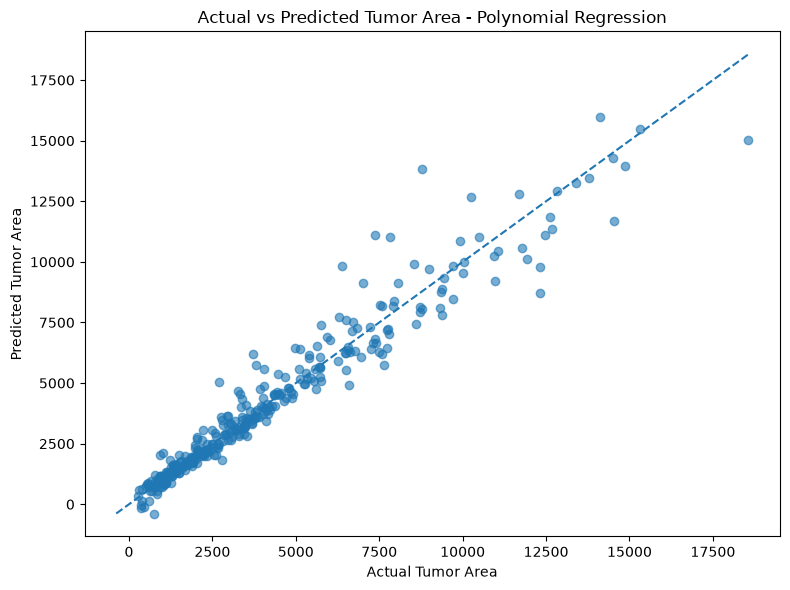

In [39]:
# Actual vs Predicted Tumor Area

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test,
    y_reg_test_pred_poly,
    alpha=0.6
)

# Perfect prediction line
min_value = min(y_reg_test.min(), y_reg_test_pred_poly.min())
max_value = max(y_reg_test.max(), y_reg_test_pred_poly.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Tumor Area")
plt.ylabel("Predicted Tumor Area")
plt.title("Actual vs Predicted Tumor Area - Polynomial Regression")

plt.tight_layout()
plt.show()

Residual Analysis:
Mean Residual: -9.89
Residual Standard Deviation: 826.71
Minimum Residual: -5051.26
Maximum Residual: 3597.35


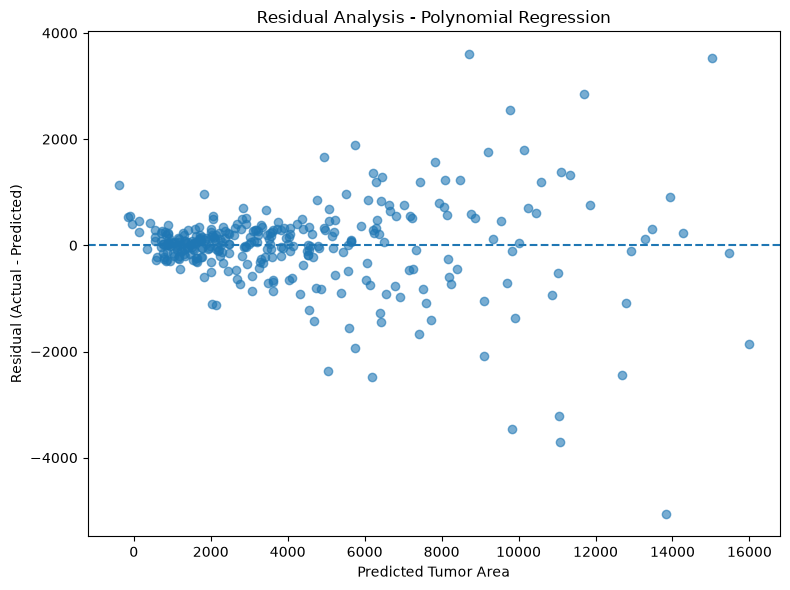

In [40]:
# Residual Analysis

residuals = y_reg_test - y_reg_test_pred_poly

print("Residual Analysis:")
print("Mean Residual:", round(np.mean(residuals), 2))
print("Residual Standard Deviation:", round(np.std(residuals), 2))
print("Minimum Residual:", round(np.min(residuals), 2))
print("Maximum Residual:", round(np.max(residuals), 2))

# Residual plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test_pred_poly,
    residuals,
    alpha=0.6
)

# Zero-error reference line
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Tumor Area")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis - Polynomial Regression")

plt.tight_layout()
plt.show()

In [41]:
# Save the final Polynomial Regression model

import joblib

model_path = r"C:\ML PROJECT\DATASET\final_polynomial_regression_model.pkl"

joblib.dump(
    best_poly_model,
    model_path
)

print("Final model saved successfully!")
print("File:", model_path)

Final model saved successfully!
File: C:\ML PROJECT\DATASET\final_polynomial_regression_model.pkl


In [42]:
# Verify saved model

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_model))

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
